In [15]:
import sys, json, math, random
sys.path.append("..")
import numpy as np
import torch
import torch.nn.functional as F
import sentencepiece as spm
from models.gpt import GPT, GPTConfig

device = "cuda" if torch.cuda.is_available() else "cpu"
sp = spm.SentencePieceProcessor(model_file="../tokenizer/kam_bpe_8k.model")

ckpt = torch.load("../checkpoints/gpt_best.pt", map_location=device)
cfg = GPTConfig(**ckpt["config"])
model = GPT(cfg).to(device)
model.load_state_dict(ckpt["model"])
model.eval()
print("step", ckpt["step"], "val loss", round(ckpt["val_loss"], 3))

step 4750 val loss 3.75


In [11]:
def sample(prompt="", n_tokens=120, temperature=0.8, top_k=50, seed=0):
    torch.manual_seed(seed)
    ids = [sp.eos_id()] + sp.encode(prompt)
    idx = torch.tensor([ids], device=device)
    out = model.generate(idx, n_tokens, temperature=temperature, top_k=top_k, stop_id=sp.eos_id())
    new = [t for t in out[0, 1:].tolist() if t != sp.eos_id()]
    return sp.decode(new)

for t in [0.5, 0.8, 1.2]:
    print(f"--- temperature {t}")
    print(sample(temperature=t, seed=1))

print("--- prompt")
print(sample("Mũndũ", seed=1))

--- temperature 0.5
(1 Akolintho 5:10) Nĩ kyaũ kĩtonya kũtũtetheesya twĩyũmbanĩsye kwĩkala nthĩ nzaũ?
--- temperature 0.8
(1 Ako.
--- temperature 1.2
Ĩandĩko ya Nthimo 5:6 yaĩtye: "Ũndũ ũngĩ wa vata kũtavanasya."
--- prompt
Mũndũ ũmwe waĩ na syana syĩtawa ata?


In [4]:
val_ids = torch.from_numpy(np.fromfile("../data/splits/val_ids.bin", dtype=np.uint16).astype(np.int64))
counts = json.load(open("../results/val_counts.json"))

@torch.no_grad()
def full_val_bpc():
    T = cfg.block_size
    total_nats = 0.0
    n_pred = 0
    for i in range(0, len(val_ids) - 1, T):
        x = val_ids[i : i + T]
        y = val_ids[i + 1 : i + T + 1]
        x = x[: len(y)]
        logits, _ = model(x[None].to(device))
        total_nats += F.cross_entropy(logits[0], y.to(device), reduction="sum").item()
        n_pred += len(y)
    return total_nats / math.log(2) / counts["val_chars"], total_nats / n_pred

bpc, nats_per_token = full_val_bpc()
print("val bpc", round(bpc, 3), "nats/token", round(nats_per_token, 3))
json.dump({"model": "gpt", "config": ckpt["config"], "step": ckpt["step"],
           "val_bpc": round(bpc, 3)}, open("../results/gpt.json", "w"), indent=2)


val bpc 1.521 nats/token 3.753


In [5]:
train_text = open("../data/splits/train.txt", encoding="utf-8").read()

def copy_check(text, n=40):
    windows = [text[i : i + n] for i in range(0, len(text) - n + 1, n)]
    if not windows:
        return 0.0
    found = sum(1 for w in windows if w in train_text)
    return found / len(windows)

samples = [sample(n_tokens=120, seed=s) for s in range(20)]
rates = [copy_check(s) for s in samples]
print("copied 40-char chunks:", round(100 * sum(rates) / len(rates), 1), "%")

copied 40-char chunks: 0.0 %


In [6]:
print(copy_check(train_text[5000:5400]))
print([len(s) for s in samples])

1.0
[92, 7, 86, 45, 91, 199, 97, 138, 129, 85, 38, 173, 199, 86, 78, 76, 97, 45, 69, 21]


In [7]:
samples = [sample(n_tokens=200, seed=s) for s in range(100)]
long = [s for s in samples if len(s) >= 40]
chunks = sum(len(s) // 40 for s in long)
rates = [copy_check(s) for s in long]
print(len(long), "samples,", chunks, "chunks checked,", round(100 * sum(rates) / len(rates), 1), "% copied")

88 samples, 166 chunks checked, 0.0 % copied


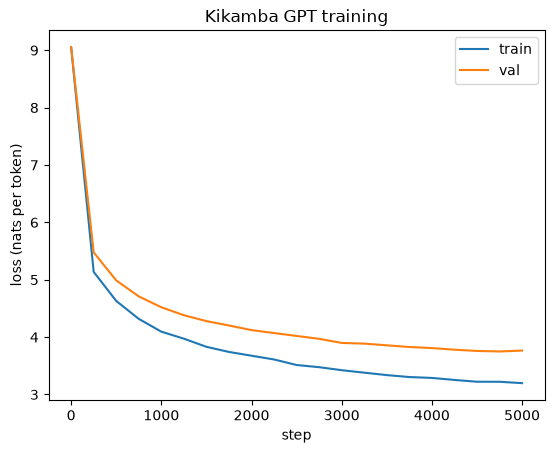

In [9]:
import matplotlib.pyplot as plt

log = json.load(open("../results/train_log.json"))
steps = [r["step"] for r in log]
plt.plot(steps, [r["train"] for r in log], label="train")
plt.plot(steps, [r["val"] for r in log], label="val")
plt.xlabel("step")
plt.ylabel("loss (nats per token)")
plt.legend()
plt.title("Kikamba GPT training")
plt.savefig("../results/gpt_loss.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
val_text = open("../data/splits/val.txt", encoding="utf-8").read()
val_docs = [d for d in val_text.split("\n\n") if len(d) > 120]

def cut(t, n=120):
    t = t[:n]
    i = t.rfind(" ")
    return t[:i] if i > 0 else t

rng = random.Random(7)
real = [("real", cut(d)) for d in rng.sample(val_docs, 10)]

fake = []
seed = 100
while len(fake) < 10:
    s = sample(n_tokens=120, seed=seed)
    seed += 1
    if len(s) > 120:
        fake.append(("model", cut(s)))

items = real + fake
rng.shuffle(items)
with open("../results/blind_gpt_sheet.txt", "w", encoding="utf-8") as f:
    for i, (_, t) in enumerate(items, 1):
        f.write(f"{i}. {t}\n\n")
with open("../results/blind_gpt_key.txt", "w", encoding="utf-8") as f:
    for i, (label, _) in enumerate(items, 1):
        f.write(f"{i}. {label}\n")
print("tries needed:", seed - 100)

tries needed: 72


In [13]:
scores = [4, 4, 4, 2, 2, 3, 2, 3, 4, 3, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2]
guess = ["?"] * 9 + ["M"] * 11

with open("../results/blind_gpt_answers_dad.txt", "w", encoding="utf-8") as f:
    for i, (s, g) in enumerate(zip(scores, guess), 1):
        f.write(f"{i} {g} {s}\n")

key = [line.split(". ")[1].strip() for line in open("../results/blind_gpt_key.txt", encoding="utf-8") if line.strip()]

for i, (s, g, k) in enumerate(zip(scores, guess, key), 1):
    print(i, "score", s, "guess", g, "truth", k)

real_scores = [s for s, k in zip(scores, key) if k == "real"]
model_scores = [s for s, k in zip(scores, key) if k == "model"]
print("average score, real lines: ", round(sum(real_scores) / len(real_scores), 2))
print("average score, model lines:", round(sum(model_scores) / len(model_scores), 2))

decided = [(g, k) for g, k in zip(guess, key) if g != "?"]
correct = sum((g == "M") == (k == "model") for g, k in decided)
print("guesses made:", len(decided), " correct:", correct)

1 score 4 guess ? truth model
2 score 4 guess ? truth real
3 score 4 guess ? truth real
4 score 2 guess ? truth real
5 score 2 guess ? truth real
6 score 3 guess ? truth real
7 score 2 guess ? truth real
8 score 3 guess ? truth model
9 score 4 guess ? truth real
10 score 3 guess M truth model
11 score 2 guess M truth real
12 score 2 guess M truth model
13 score 2 guess M truth model
14 score 2 guess M truth model
15 score 2 guess M truth model
16 score 2 guess M truth model
17 score 2 guess M truth real
18 score 3 guess M truth model
19 score 2 guess M truth real
20 score 2 guess M truth model
average score, real lines:  2.7
average score, model lines: 2.5
guesses made: 11  correct: 8


Blind test (dad, 20 lines): real lines 2.7/5, model lines 2.5/5.
He labelled 11 lines as model: 8 were model, 3 were real.
One rater, so this is an early result.

In [18]:
sys.path.append("../app")
from export_web import export_for_web

export_for_web(model, ckpt, "../tokenizer/kam_bpe_8k.model",
               "../data/splits/val.txt", "../app/web")

wrote ..\app\web: model.bin (10.5 MB), model.json, selftest.json


In [17]:
%pip install protobuf

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
t = json.load(open("../app/web/model.json", encoding="utf-8"))["tokenizer"]
print({k: v for k, v in t.items() if k != "pieces"})
for i in [14, 2176, 848]:
    print(i, repr(t["pieces"][i]))
print(sum(1 for p in t["pieces"] if p[2] == 4), "user-defined pieces")

{'normalizer': 'identity', 'add_dummy_prefix': True, 'remove_extra_whitespaces': True, 'escape_whitespaces': True, 'byte_fallback': True, 'unk_id': 0, 'eos_id': 2}
14 ['<0x0A>', 0.0, 6]
2176 ['kwi', -1916.0, 1]
848 ['▁kwi', -588.0, 1]
0 user-defined pieces
